In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import ttest_ind, mannwhitneyu, shapiro, chi2_contingency

import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")
%matplotlib inline

## PARTE 1

In [18]:
hypotheses = pd.read_csv("hypotheses_us.csv", sep=';')
display(hypotheses)

hypotheses.describe().T

,Hypothesis,Reach,Impact,Confidence,Effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1
5,Add a customer review page. This will increase...,3,2,2,3
6,Show banners with current offers and sales on ...,5,3,8,3
7,Add a subscription form to all the main pages....,10,7,8,5
8,Launch a promotion that gives users discounts ...,1,9,9,5


,count,mean,std,min,25%,50%,75%,max
Reach,9.0,4.777778,3.153481,1.0,3.0,3.0,8.0,10.0
Impact,9.0,4.777778,3.192874,1.0,3.0,3.0,7.0,10.0
Confidence,9.0,5.555556,3.045944,1.0,3.0,7.0,8.0,9.0
Effort,9.0,4.888889,2.803767,1.0,3.0,5.0,6.0,10.0


Calculando as colunas ICE e RICE


In [19]:
#Calculando ICE
hypotheses['ICE'] = (hypotheses['Impact'] * hypotheses['Confidence']) / hypotheses['Effort']

#Ordenando por ICE em ordem crescente
ice_sorted = hypotheses.sort_values(by='ICE', ascending = False)
print(ice_sorted.head(10))

                                          Hypothesis  Reach  Impact  \
8  Launch a promotion that gives users discounts ...      1       9   
0  Add two new channels for attracting traffic. T...      3      10   
7  Add a subscription form to all the main pages....     10       7   
6  Show banners with current offers and sales on ...      5       3   
2  Add product recommendation blocks to the store...      8       3   
1  Launch your own delivery service. This will sh...      2       5   
5  Add a customer review page. This will increase...      3       2   
3  Change the category structure. This will incre...      8       3   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort        ICE  
8           9       5  16.200000  
0           8       6  13.333333  
7           8       5  11.200000  
6           8       3   8.000000  
2           7       3   7.000000  
1           4      10   2.000000  
5           2       3   1.333333  
3        

In [20]:
#Calculando o RICE
hypotheses['RICE'] = (hypotheses['Reach'] * hypotheses['Impact'] * hypotheses['Confidence']) / hypotheses['Effort']

#Ordenando por RICE em ordem crescente
rice_sorted = hypotheses.sort_values(by='RICE', ascending = False)
print(rice_sorted.head(10))

                                          Hypothesis  Reach  Impact  \
7  Add a subscription form to all the main pages....     10       7   
2  Add product recommendation blocks to the store...      8       3   
0  Add two new channels for attracting traffic. T...      3      10   
6  Show banners with current offers and sales on ...      5       3   
8  Launch a promotion that gives users discounts ...      1       9   
3  Change the category structure. This will incre...      8       3   
1  Launch your own delivery service. This will sh...      2       5   
5  Add a customer review page. This will increase...      3       2   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort        ICE   RICE  
7           8       5  11.200000  112.0  
2           7       3   7.000000   56.0  
0           8       6  13.333333   40.0  
6           8       3   8.000000   40.0  
8           9       5  16.200000   16.2  
3           3       8   1.125000    9

Ao priorizar com ICE, as hipóteses com maior impacto e confiança aparecem no topo, independentemente do alcance.
Ao aplicar o RICE, o ranking muda significativamente porque o fator Reach passa a influenciar a priorização.
Hipóteses como “Adicionar formulário de inscrição” e “Adicionar blocos de recomendação” sobem no ranking, pois atingem um grande número de usuários.
Por outro lado, hipóteses como “Lançar promoção com descontos”, que tinham alta prioridade no ICE, caem no ranking do RICE devido ao baixo alcance.
Isso mostra que o RICE é mais adequado quando queremos priorizar hipóteses que geram impacto em escala, enquanto o ICE favorece hipóteses com impacto individual alto, mas alcance limitado.

## Parte 2

In [21]:
#Carregamento e pré processamento dos dados

orders = pd.read_csv('orders_us.csv') 
visits = pd.read_csv('visits_us .csv') 

orders = orders.rename(columns={ 
    'transactionId': 'transaction_id', 
    'visitorId': 'visitor_id', 
    'date': 'date', 
    'revenue': 'revenue', 
    'group': 'group' }) 

visits = visits.rename(columns={ 
    'date': 'date', 
    'group': 'group',
    'visits': 'visits' })

orders['date'] = pd.to_datetime(orders['date']) 
visits['date'] = pd.to_datetime(visits['date'])

print(orders.head())
print()
print(visits.head())

   transaction_id  visitor_id       date  revenue group
0      3667963787  3312258926 2019-08-15     30.4     B
1      2804400009  3642806036 2019-08-15     15.2     B
2      2961555356  4069496402 2019-08-15     10.2     A
3      3797467345  1196621759 2019-08-15    155.1     B
4      2282983706  2322279887 2019-08-15     40.5     B

        date group  visits
0 2019-08-01     A     719
1 2019-08-02     A     619
2 2019-08-03     A     507
3 2019-08-04     A     717
4 2019-08-05     A     756


In [22]:
print(orders)

      transaction_id  visitor_id       date  revenue group
0         3667963787  3312258926 2019-08-15     30.4     B
1         2804400009  3642806036 2019-08-15     15.2     B
2         2961555356  4069496402 2019-08-15     10.2     A
3         3797467345  1196621759 2019-08-15    155.1     B
4         2282983706  2322279887 2019-08-15     40.5     B
...              ...         ...        ...      ...   ...
1192      2662137336  3733762160 2019-08-14    100.8     B
1193      2203539145   370388673 2019-08-14     50.1     A
1194      1807773912   573423106 2019-08-14    165.3     A
1195      1947021204  1614305549 2019-08-14      5.5     A
1196      3936777065  2108080724 2019-08-15   3120.1     B

[1197 rows x 5 columns]


In [23]:
#remover usuários que aparecem nos dois grupos
duplicated_users = orders.groupby('visitor_id')['group'].nunique()
duplicated_users = duplicated_users[duplicated_users > 1].index
orders_clean = orders[~orders['visitor_id'].isin(duplicated_users)]
print(orders_clean)

      transaction_id  visitor_id       date  revenue group
0         3667963787  3312258926 2019-08-15     30.4     B
1         2804400009  3642806036 2019-08-15     15.2     B
3         3797467345  1196621759 2019-08-15    155.1     B
4         2282983706  2322279887 2019-08-15     40.5     B
5          182168103   935554773 2019-08-15     35.0     B
...              ...         ...        ...      ...   ...
1191      3592955527   608641596 2019-08-14    255.7     B
1192      2662137336  3733762160 2019-08-14    100.8     B
1193      2203539145   370388673 2019-08-14     50.1     A
1194      1807773912   573423106 2019-08-14    165.3     A
1196      3936777065  2108080724 2019-08-15   3120.1     B

[1016 rows x 5 columns]


# Receita acumulada por Grupo

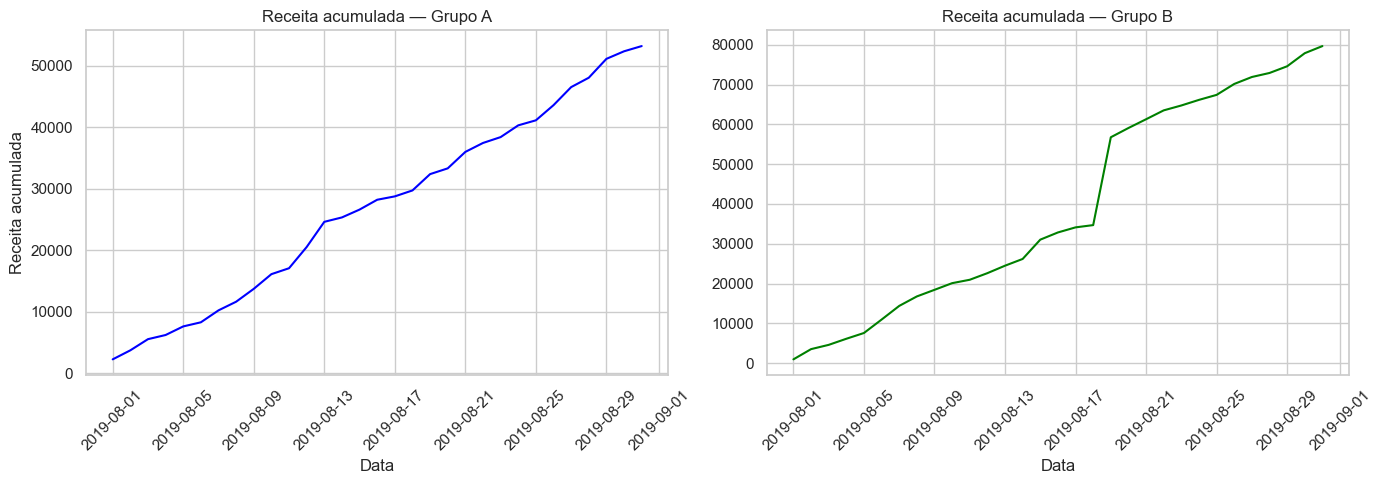

In [24]:
cumulative_revenue = (
    orders_clean
        .groupby(['date','group'])['revenue']
        .sum()
        .groupby(level=1)
        .cumsum()
        .reset_index())

#print(cumulative_revenue)

plt.figure(figsize=(14,5))  

# Subplot 1: Grupo A 
plt.subplot(1, 2, 1)
grupo_a = cumulative_revenue[cumulative_revenue['group'] == 'A']
plt.plot(grupo_a['date'], grupo_a['revenue'], color='blue')
plt.title("Receita acumulada — Grupo A")
plt.xlabel("Data")
plt.ylabel("Receita acumulada")
plt.xticks(rotation=45)
plt.grid(True)

# Subplot 2: Grupo B 
plt.subplot(1, 2, 2)
grupo_b = cumulative_revenue[cumulative_revenue['group'] == 'B']
plt.plot(grupo_b['date'], grupo_b['revenue'], color='green')
plt.title("Receita acumulada — Grupo B")
plt.xlabel("Data")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


Conclusão:
Grupo B acumulou mais receita (80k) que A (50k).
A curva de B teve saltos bruscos, enquanto A foi estável e gradual.

Conjecturas:
Grupo B pode ter sido impactado por promoções ou eventos específicos que aumentaram a receita em certos dias.
Os usuários do grupo B podem ter perfil mais impulsivo ou propenso a gastar, enquanto os do grupo A são mais regulares.
A maior receita de B pode vir de menos usuários gastando mais, enquanto A tem mais usuários gastando valores menores.

# Ticket Médio Acumulado por Grupo

         date group  revenue  transaction_id   avg_order
0  2019-08-01     A   2266.6              23   98.547826
1  2019-08-01     B    967.2              17   56.894118
2  2019-08-02     A   3734.9              42   88.926190
3  2019-08-02     B   3535.3              40   88.382500
4  2019-08-03     A   5550.1              66   84.092424
..        ...   ...      ...             ...         ...
57 2019-08-29     B  74576.7             510  146.228824
58 2019-08-30     A  52363.7             460  113.834130
59 2019-08-30     B  77863.5             531  146.635593
60 2019-08-31     A  53212.0             468  113.700855
61 2019-08-31     B  79651.2             548  145.348905

[62 rows x 5 columns]


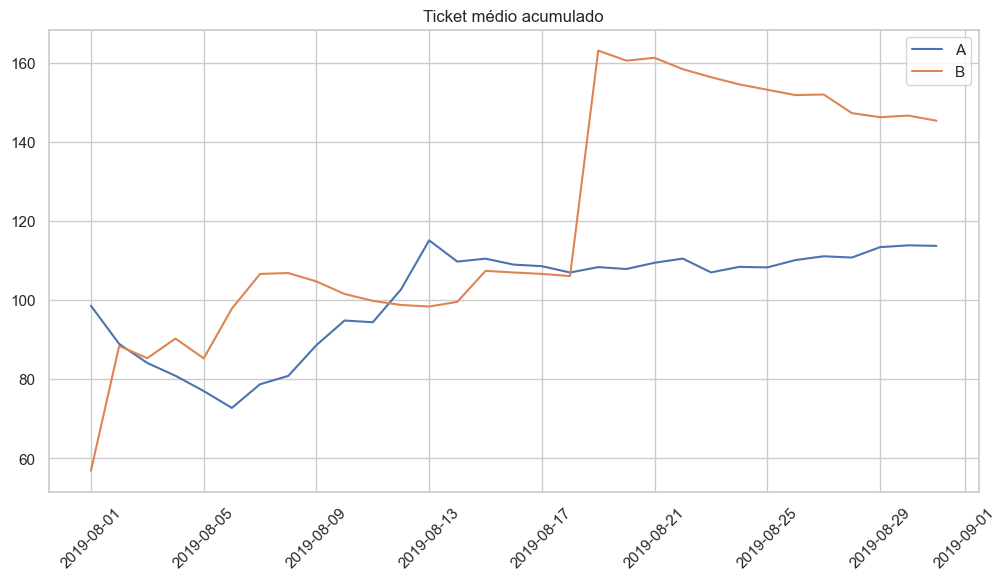

In [25]:
cumulative_orders = (
    orders_clean
    .groupby(['date','group'])['transaction_id']
    .count()
    .groupby(level=1)
    .cumsum()
    .reset_index()
)

merged = cumulative_revenue.merge(
    cumulative_orders,
    on=['date','group'])


merged['avg_order'] = merged['revenue'] / merged['transaction_id']
print(merged)
plt.figure(figsize=(12,6))
for group in ['A','B']:
    plt.plot(
        merged[merged['group']==group]['date'],
        merged[merged['group']==group]['avg_order'],
        label=group
    )
plt.legend()
plt.xticks(rotation=45)
plt.title('Ticket médio acumulado')
plt.show()


Conclusão:
Grupo B teve ticket médio maior na maioria dos dias, com um pico (170) seguido de queda.
Grupo A manteve ticket médio mais estável (110).

Conjecturas:
O pico de B pode estar ligado a compras concentradas em poucos usuários ou a um evento que incentivou gastos maiores.
A queda posterior sugere que o comportamento não foi sustentável, indicando volatilidade.
Grupo A pode representar um padrão de consumo mais previsível e confiável, mesmo com valores menores.

# Diferença relativa no ticket médio acumulado

group                A           B
date                              
2019-08-01   98.547826   56.894118
2019-08-02   88.926190   88.382500
2019-08-03   84.092424   85.312963
2019-08-04   80.851948   90.272059
2019-08-05   77.006061   85.256180
2019-08-06   72.736842   97.831250
2019-08-07   78.723077  106.612593
2019-08-08   80.825000  106.831847
2019-08-09   88.606452  104.709091
2019-08-10   94.832353  101.533333
2019-08-11   94.391713   99.804762
2019-08-12  102.668500   98.763319
2019-08-13  115.096262   98.358635
2019-08-14  109.728139   99.557795
2019-08-15  110.466805  107.381315
2019-08-16  108.963707  106.971336
2019-08-17  108.566415  106.613125
2019-08-18  106.962950  106.069419
2019-08-19  108.325418  163.073563
2019-08-20  107.848867  160.527717
2019-08-21  109.435258  161.248421
2019-08-22  110.487021  158.363840
2019-08-23  106.989415  156.359420
2019-08-24  108.390591  154.529206
2019-08-25  108.261842  153.167727
2019-08-26  110.111869  151.814069
2019-08-27  111.0715

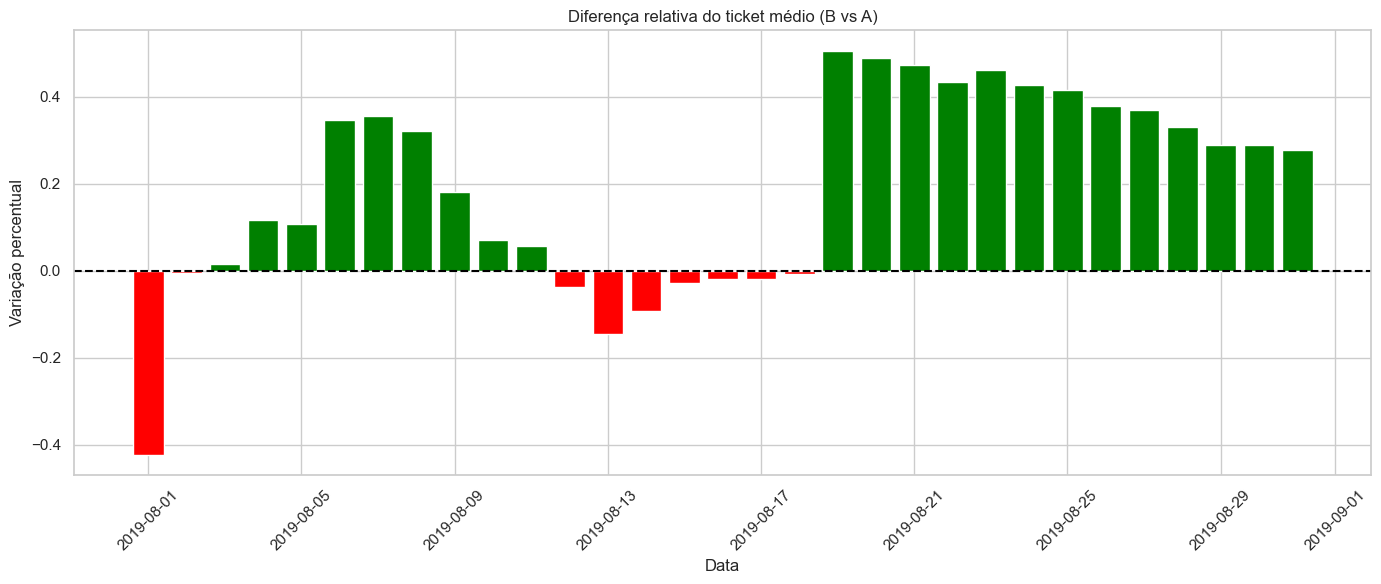

In [26]:
pivot_avg = merged.pivot(index='date', columns='group', values='avg_order')

print(pivot_avg)

relative_diff = pivot_avg['B'] / pivot_avg['A'] - 1

plt.figure(figsize=(14,6))

# Cores: verde se B > A, vermelho se B < A
colors = ['green' if val > 0 else 'red' for val in relative_diff.values]

plt.bar(relative_diff.index, relative_diff.values, color=colors)
plt.axhline(y=0, color='black', linestyle='--')
plt.xticks(rotation=45)
plt.title('Diferença relativa do ticket médio (B vs A)')
plt.ylabel('Variação percentual')
plt.xlabel('Data')
plt.tight_layout()
plt.show()


Conclusão:
A maioria das barras ficou verde (B > A).
Poucos dias vermelhos, indicando que B superou A na maior parte do tempo.

Conjecturas:
As oscilações podem indicar que o grupo B é mais sensível a fatores externos (promoções, sazonalidade).
Grupo A pode ser menos afetado por variações, mostrando resiliência.

# Taxa de Conversão de cada grupo

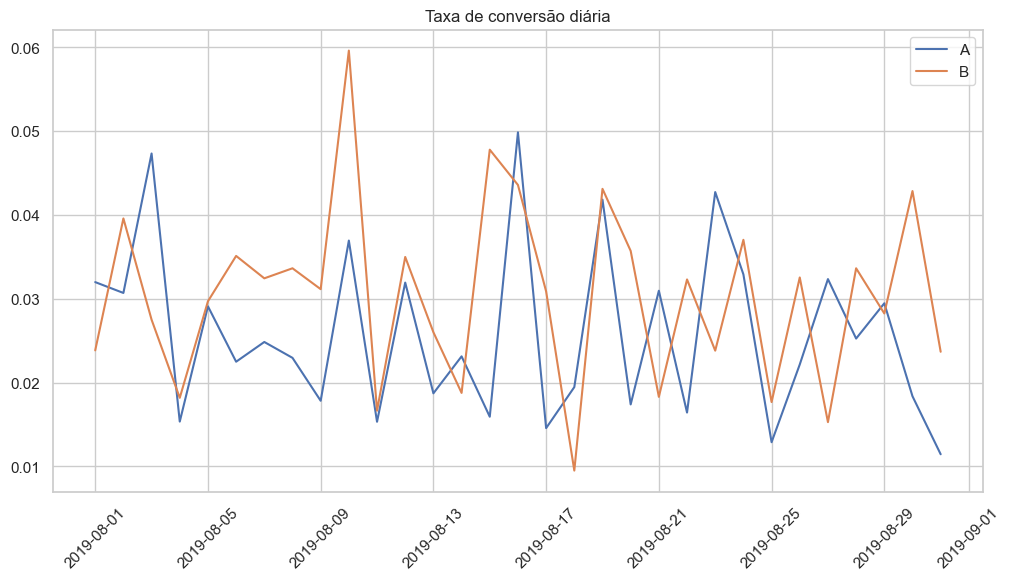

In [27]:
daily_orders = orders_clean.groupby(['date','group'])['transaction_id'].nunique().reset_index()
daily_visits = visits.copy()

conversion = daily_orders.merge(daily_visits, on=['date','group'])
conversion['conversion'] = conversion['transaction_id'] / conversion['visits']


plt.figure(figsize=(12,6))
for group in ['A','B']:
    plt.plot(
        conversion[conversion['group']==group]['date'],
        conversion[conversion['group']==group]['conversion'],
        label=group
    )
plt.legend()
plt.xticks(rotation=45)
plt.title('Taxa de conversão diária')
plt.show()



Conclusão:
Ambos os grupos apresentam flutuações diárias na taxa de conversão.
Em alguns dias, o grupo A converte mais; em outros, o grupo B.
Não há uma dominância clara como vimos no ticket médio ou na receita.

Conjecturas:
Mesmo com conversão instável, o grupo B teve ticket médio maior e receita acumulada superior.
Isso sugere que o grupo B compensa uma conversão menor com pedidos mais valiosos.
O grupo A pode estar convertendo mais usuários, mas com menor impacto financeiro por pedido.

# Diferença relativa da conversão cumulativa

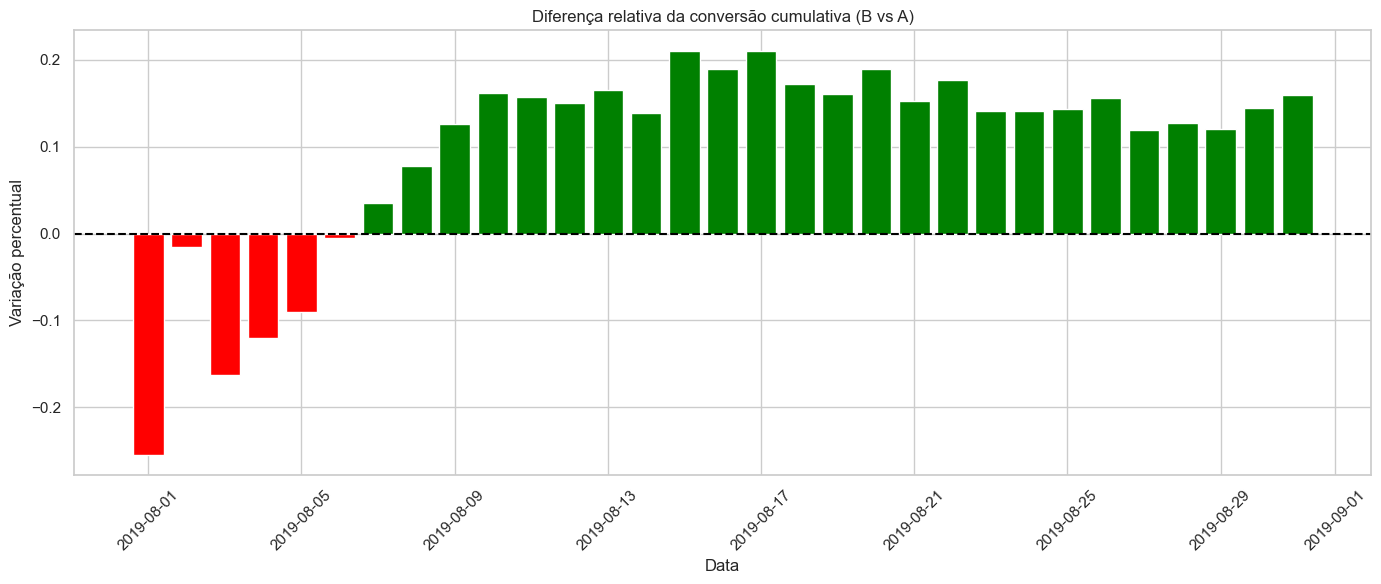

In [28]:

cumulative_visits = (
    visits.groupby(['date','group'])['visits']
    .sum()
    .groupby(level=1)
    .cumsum()
    .reset_index()
)

cumulative_orders2 = (
    orders_clean.groupby(['date','group'])['transaction_id']
    
.nunique()
    .groupby(level=1)
    .cumsum()
    .reset_index()
)

conv_cum = cumulative_orders2.merge(cumulative_visits, on=['date','group'])
conv_cum['conversion'] = conv_cum['transaction_id'] / conv_cum['visits']

pivot_conv = conv_cum.pivot(index='date', columns='group', values='conversion')
relative_conv = pivot_conv['B'] / pivot_conv['A'] - 1

plt.figure(figsize=(14,6))

colors = ['green' if val > 0 else 'red' for val in relative_conv.values]

plt.bar(relative_conv.index, relative_conv.values, color=colors)
plt.axhline(y=0, color='black', linestyle='--')
plt.xticks(rotation=45)
plt.title('Diferença relativa da conversão cumulativa (B vs A)')
plt.ylabel('Variação percentual')
plt.xlabel('Data')
plt.tight_layout()
plt.show()




In [29]:
print(relative_conv)

date
2019-08-01   -0.254650
2019-08-02   -0.015235
2019-08-03   -0.162759
2019-08-04   -0.120659
2019-08-05   -0.090595
2019-08-06   -0.005060
2019-08-07    0.035107
2019-08-08    0.078136
2019-08-09    0.125490
2019-08-10    0.161923
2019-08-11    0.157237
2019-08-12    0.150162
2019-08-13    0.165372
2019-08-14    0.138780
2019-08-15    0.209913
2019-08-16    0.189353
2019-08-17    0.210440
2019-08-18    0.171626
2019-08-19    0.160984
2019-08-20    0.189574
2019-08-21    0.152862
2019-08-22    0.177206
2019-08-23    0.141483
2019-08-24    0.140504
2019-08-25    0.143810
2019-08-26    0.156479
2019-08-27    0.118835
2019-08-28    0.126808
2019-08-29    0.120539
2019-08-30    0.144135
2019-08-31    0.159798
dtype: float64


Conclusão:
No início do período, o grupo B teve conversão inferior ao grupo A (barras vermelhas).
A partir de meados de agosto, o grupo B passou a ter conversão superior (barras verdes), mantendo essa vantagem até o final.
Conjecturas:
Os usuários do grupo B podem demorar mais para converter, mas quando o fazem, convertem em massa e com mais valor, como vimos no ticket médio.
O grupo B pode ter um funil mais longo: usuários demoram mais para converter, mas são mais qualificados.
O grupo A converte mais rápido, mas com menor impacto financeiro.
A virada pode coincidir com uma mudança de experiência.

# Percentis 95 e 99 — pedidos por usuário

In [30]:
orders_per_user = orders_clean.groupby('visitor_id')['transaction_id'].nunique()

np.percentile(orders_per_user, [95, 99])

array([1., 2.])

In [31]:
#IQR (Intervalo Interquartil)
q1 = np.percentile(orders_per_user, 25)
q3 = np.percentile(orders_per_user, 75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

limite_inferior, limite_superior

(np.float64(1.0), np.float64(1.0))

In [32]:
# Z‑score (desvio padrão)
media = orders_per_user.mean()
desvio = orders_per_user.std()

z_scores = (orders_per_user - media) / desvio

outliers = orders_per_user[np.abs(z_scores) > 3]
outliers

visitor_id
249864742     3
366673373     2
406208401     2
522292794     2
611059232     3
678354126     2
759473111     2
1404560065    2
1617417821    2
1637811943    2
1772171838    2
1985475298    2
2025197455    2
2096506107    2
2108163459    3
2232111114    2
2306096143    2
2366521417    2
2397843657    2
2706377257    2
2733145037    2
2742574263    3
2744017357    2
2892265953    2
2988190573    3
3077396270    2
3332057097    2
3362039251    2
3379260072    2
3469608676    2
3908431265    3
3935952912    2
3941503500    2
3967698036    3
4109358064    2
4134830387    2
Name: transaction_id, dtype: int64

Conclusão: 
95% dos usuários têm apenas 1 pedido.
99% têm no máximo 2 pedidos.
Portanto, 3 ou mais pedidos já são raros e podem ser tratados como anomalias.

# Significância estatística da diferença na conversão - dados brutos

In [33]:
cumulative_visits = (
    visits.groupby(['date','group'])['visits']
    .sum()
    .reset_index()
)

cumulative_orders2 = (
    orders_clean.groupby(['date','group'])['transaction_id']
    .nunique()
    .reset_index()
)

conv_cum = cumulative_orders2.merge(cumulative_visits, on=['date','group'])
conv_cum['conversion'] = conv_cum['transaction_id'] / conv_cum['visits']

conv_cum


,date,group,transaction_id,visits,conversion
0,2019-08-01,A,23,719,0.031989
1,2019-08-01,B,17,713,0.023843
2,2019-08-02,A,19,619,0.030695
3,2019-08-02,B,23,581,0.039587
4,2019-08-03,A,24,507,0.047337
...,...,...,...,...,...
57,2019-08-29,B,15,531,0.028249
58,2019-08-30,A,9,490,0.018367
59,2019-08-30,B,21,490,0.042857
60,2019-08-31,A,8,699,0.011445


In [34]:
# # Teste de Shapiro-Wilk para cada grupo
def show_shappiro_results(stats_result, p_value, group):
    print(f"Grupo {group} - Shapiro-Wilk: Estatística = {stats_result:.3f}, p-value = {p_value:.3f}")

    if p_value < 0.05:
        print(f"Rejeitamos a Hipótese Nula")
        print(f"Há evidências de que os dados NÃO seguem uma distribuição normal.")
    else:
        print(f"Não rejeitamos a Hipótese Nula")
        print(f"Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).")

    print()

    return None

In [35]:
stat_a, p_a = shapiro(conv_cum.loc[conv_cum['group'] == 'A','conversion'])
stat_b, p_b = shapiro(conv_cum.loc[conv_cum['group'] == 'B','conversion'])

# Resultados
show_shappiro_results(stat_a, p_a, 'A')
show_shappiro_results(stat_b, p_b, 'B')

Grupo A - Shapiro-Wilk: Estatística = 0.934, p-value = 0.056
Não rejeitamos a Hipótese Nula
Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).

Grupo B - Shapiro-Wilk: Estatística = 0.976, p-value = 0.703
Não rejeitamos a Hipótese Nula
Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).



In [36]:
from scipy import stats

stat_t, p_value = stats.ttest_ind(conv_cum.loc[conv_cum['group'] == 'A','conversion'], conv_cum.loc[conv_cum['group'] == 'B','conversion'])

print(f"Estatística T-test 2 Sample = {stat_t:.3f}, p-value = {p_value:.3f}")

if p_value < 0.05:
    print("Rejeitamos a Hipótese Nula.")
    print("Há evidências de que os grupos são estatisticamente distintos.")
else:
    print("Não rejeitamos a Hipótese Nula.")
    print("Não há evidências de que os grupos são estatisticamente distintos.")

Estatística T-test 2 Sample = -1.693, p-value = 0.096
Não rejeitamos a Hipótese Nula.
Não há evidências de que os grupos são estatisticamente distintos.


* Conclusão: Não há diferença estatisticamente significativa na conversão entre os grupos A e B.
Conjectura: Os grupos apresentam comportamento semelhante em termos de conversão inicial.

# Significância estatística da diferença no tamanho médio - dados brutos

In [37]:
cumulative_orders = (
    orders_clean
    .groupby(['date','group'])['transaction_id']
    .count()
    .reset_index()
)

merged = cumulative_revenue.merge(
    cumulative_orders,
    on=['date','group'])

merged['avg_order'] = merged['revenue'] / merged['transaction_id']

merged


,date,group,revenue,transaction_id,avg_order
0,2019-08-01,A,2266.6,23,98.547826
1,2019-08-01,B,967.2,17,56.894118
2,2019-08-02,A,3734.9,19,196.573684
3,2019-08-02,B,3535.3,23,153.708696
4,2019-08-03,A,5550.1,24,231.254167
...,...,...,...,...,...
57,2019-08-29,B,74576.7,15,4971.780000
58,2019-08-30,A,52363.7,9,5818.188889
59,2019-08-30,B,77863.5,21,3707.785714
60,2019-08-31,A,53212.0,8,6651.500000


In [38]:
## Teste de Shapiro-Wilk para cada grupo
def show_shappiro_results(stats_result, p_value, group):
    print(f"Grupo {group} - Shapiro-Wilk: Estatística = {stats_result:.3f}, p-value = {p_value:.3f}")

    if p_value < 0.05:
        print(f"Rejeitamos a Hipótese Nula")
        print(f"Há evidências de que os dados NÃO seguem uma distribuição normal.")
    else:
        print(f"Não rejeitamos a Hipótese Nula")
        print(f"Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).")

    print()

    return None


In [39]:
stat_a, p_a = shapiro(merged.loc[merged['group'] == 'A','avg_order'])
stat_b, p_b = shapiro(merged.loc[merged['group'] == 'B','avg_order'])

# Resultados
show_shappiro_results(stat_a, p_a, 'A')
show_shappiro_results(stat_b, p_b, 'B')

Grupo A - Shapiro-Wilk: Estatística = 0.907, p-value = 0.011
Rejeitamos a Hipótese Nula
Há evidências de que os dados NÃO seguem uma distribuição normal.

Grupo B - Shapiro-Wilk: Estatística = 0.914, p-value = 0.016
Rejeitamos a Hipótese Nula
Há evidências de que os dados NÃO seguem uma distribuição normal.



In [40]:
mw_stat, p_val_mw = mannwhitneyu(merged.loc[merged['group'] == 'A','avg_order'], merged.loc[merged['group'] == 'B','avg_order'])

print(f"Estatística Mann-Whitney = {mw_stat:.3f}, p-value = {p_val_mw:.3f}")

if p_val_mw < 0.05:
    print("Rejeitamos a Hipótese Nula.")
    print("Há evidências de que os grupos são estatisticamente distintos.")
else:
    print("Não rejeitamos a Hipótese Nula.")
    print("Não há evidências de que os grupos são estatisticamente distintos.")


Estatística Mann-Whitney = 451.000, p-value = 0.683
Não rejeitamos a Hipótese Nula.
Não há evidências de que os grupos são estatisticamente distintos.


* Conclusão: Não há diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos A e B.
Conjectura: O ticket médio não foi impactado pela condição experimental, sugerindo estabilidade no comportamento de compra.

# Significância estatística da diferença na conversão - dados filtrados

In [41]:
def remove_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series >= lower_bound) & (series <= upper_bound)]

In [42]:
cumulative_visits = (
    visits.groupby(['date','group'])['visits']
    .sum()
    .reset_index()
)

cumulative_orders2 = (
    orders_clean.groupby(['date','group'])['transaction_id']
    .nunique()
    .reset_index()
)

conv_cum = cumulative_orders2.merge(cumulative_visits, on=['date','group'])
conv_cum['conversion'] = conv_cum['transaction_id'] / conv_cum['visits']

#pivot_conv = conv_cum.pivot(index='date', columns='group', values='conversion')
#relative_conv = pivot_conv['B'] / pivot_conv['A'] - 1
conv_cum


,date,group,transaction_id,visits,conversion
0,2019-08-01,A,23,719,0.031989
1,2019-08-01,B,17,713,0.023843
2,2019-08-02,A,19,619,0.030695
3,2019-08-02,B,23,581,0.039587
4,2019-08-03,A,24,507,0.047337
...,...,...,...,...,...
57,2019-08-29,B,15,531,0.028249
58,2019-08-30,A,9,490,0.018367
59,2019-08-30,B,21,490,0.042857
60,2019-08-31,A,8,699,0.011445


In [ ]:
#Filtrando e removendo outliers
conv_cum_a = remove_outliers(conv_cum.loc[conv_cum['group'] == 'A','conversion'])
conv_cum_b = remove_outliers(conv_cum.loc[conv_cum['group'] == 'B','conversion'])

conv_cum_limpo = conv_cum.loc[conv_cum_a.index.union(conv_cum_b.index)]

ValueError: operands could not be broadcast together with shapes (31,) (30,) 

In [ ]:
# # Teste de Shapiro-Wilk para cada grupo
def show_shappiro_results(stats_result, p_value, group):
    print(f"Grupo {group} - Shapiro-Wilk: Estatística = {stats_result:.3f}, p-value = {p_value:.3f}")

    if p_value < 0.05:
        print(f"Rejeitamos a Hipótese Nula")
        print(f"Há evidências de que os dados NÃO seguem uma distribuição normal.")
    else:
        print(f"Não rejeitamos a Hipótese Nula")
        print(f"Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).")

    print()

    return None


In [ ]:
stat_a, p_a = shapiro(conv_cum_limpo.loc[conv_cum_limpo['group'] == 'A','conversion'])
stat_b, p_b = shapiro(conv_cum_limpo.loc[conv_cum_limpo['group'] == 'B','conversion'])

# Resultados
show_shappiro_results(stat_a, p_a, 'A')
show_shappiro_results(stat_b, p_b, 'B')

Grupo A - Shapiro-Wilk: Estatística = 0.934, p-value = 0.056
Não rejeitamos a Hipótese Nula
Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).

Grupo B - Shapiro-Wilk: Estatística = 0.978, p-value = 0.761
Não rejeitamos a Hipótese Nula
Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).



In [ ]:
from scipy import stats

stat_t, p_value = stats.ttest_ind(conv_cum_limpo.loc[conv_cum_limpo['group'] == 'A','conversion'], conv_cum_limpo.loc[conv_cum_limpo['group'] == 'B','conversion'])

print(f"Estatística T-test 2 Sample = {stat_t:.3f}, p-value = {p_value:.3f}")

if p_value < 0.05:
    print("Rejeitamos a Hipótese Nula.")
    print("Há evidências de que os grupos são estatisticamente distintos.")
else:
    print("Não rejeitamos a Hipótese Nula.")
    print("Não há evidências de que os grupos são estatisticamente distintos.")

Estatística T-test 2 Sample = -1.403, p-value = 0.166
Não rejeitamos a Hipótese Nula.
Não há evidências de que os grupos são estatisticamente distintos.


* Conclusão: Não há diferença estatisticamente significativa na conversão entre os grupos A e B.

Conjectura: A filtragem não alterou o resultado, reforçando que a conversão é estável entre os grupos.

# Significância estatística da diferença no tamanho médio - dados filtrados

In [ ]:
def remove_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series >= lower_bound) & (series <= upper_bound)]

In [ ]:

cumulative_orders = (
    orders_clean
    .groupby(['date','group'])['transaction_id']
    .count()
    .reset_index()
)

merged = cumulative_revenue.merge(
    cumulative_orders,
    on=['date','group'])

merged['avg_order'] = merged['revenue'] / merged['transaction_id']

#pivot_avg = merged.pivot(index='date', columns='group', values='avg_order')

#ticket_diff = pivot_avg['B'] / pivot_avg['A'] - 1

merged


,date,group,revenue,transaction_id,avg_order
0,2019-08-01,A,2266.6,23,98.547826
1,2019-08-01,B,967.2,17,56.894118
2,2019-08-02,A,3734.9,19,196.573684
3,2019-08-02,B,3535.3,23,153.708696
4,2019-08-03,A,5550.1,24,231.254167
...,...,...,...,...,...
57,2019-08-29,B,74576.7,15,4971.780000
58,2019-08-30,A,52363.7,9,5818.188889
59,2019-08-30,B,77863.5,21,3707.785714
60,2019-08-31,A,53212.0,8,6651.500000


In [ ]:
#Filtrando e removendo outliers
avg_order_a = remove_outliers(merged.loc[merged['group'] == 'A','avg_order'])
avg_order_b = remove_outliers(merged.loc[merged['group'] == 'B','avg_order'])

merged_limpo = merged.loc[avg_order_a.index.union(avg_order_b.index)]

,date,group,revenue,transaction_id,avg_order
0,2019-08-01,A,2266.6,23,98.547826
1,2019-08-01,B,967.2,17,56.894118
2,2019-08-02,A,3734.9,19,196.573684
3,2019-08-02,B,3535.3,23,153.708696
4,2019-08-03,A,5550.1,24,231.254167
...,...,...,...,...,...
56,2019-08-29,A,51134.8,17,3007.929412
57,2019-08-29,B,74576.7,15,4971.780000
58,2019-08-30,A,52363.7,9,5818.188889
59,2019-08-30,B,77863.5,21,3707.785714


In [ ]:
## Teste de Shapiro-Wilk para cada grupo
def show_shappiro_results(stats_result, p_value, group):
    print(f"Grupo {group} - Shapiro-Wilk: Estatística = {stats_result:.3f}, p-value = {p_value:.3f}")

    if p_value < 0.05:
        print(f"Rejeitamos a Hipótese Nula")
        print(f"Há evidências de que os dados NÃO seguem uma distribuição normal.")
    else:
        print(f"Não rejeitamos a Hipótese Nula")
        print(f"Não há evidências suficientes para dizer que os dados fogem de uma distribuição normal (podemos considerá-los aproximadamente normais).")

    print()

    return None



In [ ]:
stat_a, p_a = shapiro(merged_limpo.loc[merged_limpo['group'] == 'A','avg_order'])
stat_b, p_b = shapiro(merged_limpo.loc[merged_limpo['group'] == 'B','avg_order'])

# Resultados
show_shappiro_results(stat_a, p_a, 'A')
show_shappiro_results(stat_b, p_b, 'B')

Grupo A - Shapiro-Wilk: Estatística = 0.924, p-value = 0.035
Rejeitamos a Hipótese Nula
Há evidências de que os dados NÃO seguem uma distribuição normal.

Grupo B - Shapiro-Wilk: Estatística = 0.914, p-value = 0.016
Rejeitamos a Hipótese Nula
Há evidências de que os dados NÃO seguem uma distribuição normal.



In [ ]:
mw_stat, p_val_mw = mannwhitneyu(merged_limpo.loc[merged_limpo['group'] == 'A','avg_order'], merged_limpo.loc[merged_limpo['group'] == 'B','avg_order'])

print(f"Estatística Mann-Whitney = {mw_stat:.3f}, p-value = {p_val_mw:.3f}")

if p_val_mw < 0.05:
    print("Rejeitamos a Hipótese Nula.")
    print("Há evidências de que os grupos são estatisticamente distintos.")
else:
    print("Não rejeitamos a Hipótese Nula.")
    print("Não há evidências de que os grupos são estatisticamente distintos.")


Estatística Mann-Whitney = 420.000, p-value = 0.521
Não rejeitamos a Hipótese Nula.
Não há evidências de que os grupos são estatisticamente distintos.


* Conclusão: Não há diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos A e B.
Conjectura: Mesmo após remover outliers, os grupos mantêm padrões semelhantes de ticket médio.

# Decisão Final
Com base nos testes estatísticos realizados (t-test e Mann-Whitney), não foram encontradas diferenças significativas entre os grupos A e B, tanto na taxa de conversão quanto no tamanho médio dos pedidos. 
A decisão é encerrar o teste e concluir que não há diferença estatística entre os grupos.

</div><div class="alert alert-block alert-success">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- Os testes de hipóteses foram conduzidos corretamente
- O `p-value` foi apresentado
- As conclusões foram apresentadas
</div>